YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  1 of 1 completed



Epoch 1/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 6s 97ms/step - loss: 0.0330 - val_loss: 0.0119
Epoch 2/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 87ms/step - loss: 0.0051 - val_loss: 0.0100
Epoch 3/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - loss: 0.0042 - val_loss: 0.0088
Epoch 4/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - loss: 0.0037 - val_loss: 0.0048
Epoch 5/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - loss: 0.0037 - val_loss: 0.0076
Epoch 6/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - loss: 0.0030 - val_loss: 0.0011
Epoch 7/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - loss: 0.0038 - val_loss: 0.0026
Epoch 8/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 9/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - loss: 0.0026 - val_loss: 0.0016
Epoch 10/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - loss: 0.0020 - val_loss: 0.0015
Epoch 11/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - loss: 0.0022 - val_loss: 0.0023
Epoch 12/60
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - loss: 0.

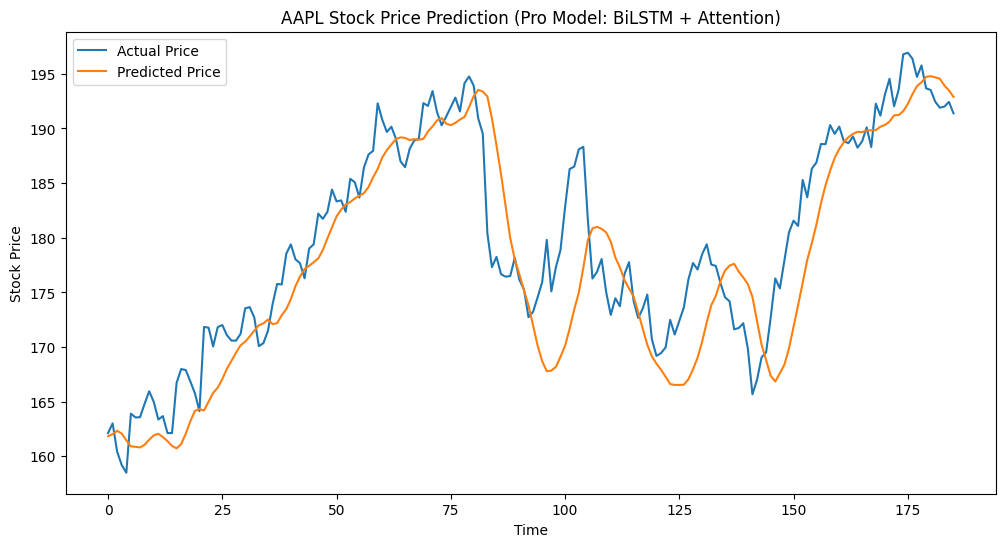

Test Mean Squared Error: 24.2178


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional, Attention, Input, Layer
from tensorflow.keras.models import Model
import tensorflow as tf

# Step 1: Download stock data
ticker = "AAPL"
data = yf.download(ticker, start="2020-01-01", end="2024-01-01")

# Step 2: Calculate Technical Indicators
# Bollinger Bands
data['MiddleBand'] = data['Close'].rolling(window=20).mean()
data['StdDev'] = data['Close'].rolling(window=20).std()
data['UpperBand'] = data['MiddleBand'] + (2 * data['StdDev'])
data['LowerBand'] = data['MiddleBand'] - (2 * data['StdDev'])

# MACD
data['EMA12'] = data['Close'].ewm(span=12, adjust=False).mean()
data['EMA26'] = data['Close'].ewm(span=26, adjust=False).mean()
data['MACD'] = data['EMA12'] - data['EMA26']
data['Signal_Line'] = data['MACD'].ewm(span=9, adjust=False).mean()

# RSI
delta = data['Close'].diff()
gain = delta.clip(lower=0)
loss = -1 * delta.clip(upper=0)
avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()
rs = avg_gain / avg_loss
data['RSI'] = 100 - (100 / (1 + rs))

# Step 3: Prepare dataset
data = data[['Close', 'MiddleBand', 'UpperBand', 'LowerBand', 'MACD', 'Signal_Line', 'RSI']].dropna()

# Scale features
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)

# Step 4: Create sequences
X = []
y = []
sequence_length = 60

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i, 1:])  # features (skip Close)
    y.append(scaled_data[i, 0])  # target: Close

X, y = np.array(X), np.array(y)

# Train/test split
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# Step 5: Build model (Bidirectional LSTM + Attention)

class AttentionLayer(Layer):
    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(name='attention_weight', shape=(input_shape[-1], 1),
                                 initializer='random_normal', trainable=True)
        self.b = self.add_weight(name='attention_bias', shape=(input_shape[1], 1),
                                 initializer='zeros', trainable=True)
        super(AttentionLayer, self).build(input_shape)

    def call(self, inputs):
        e = tf.keras.backend.tanh(tf.keras.backend.dot(inputs, self.W) + self.b)
        a = tf.keras.backend.softmax(e, axis=1)
        output = inputs * a
        return tf.keras.backend.sum(output, axis=1)

input_layer = Input(shape=(X_train.shape[1], X_train.shape[2]))
x = Bidirectional(LSTM(units=60, return_sequences=True))(input_layer)
x = Dropout(0.3)(x)
x = AttentionLayer()(x)
x = Dense(32, activation='relu')(x)
output_layer = Dense(1)(x)

model = Model(inputs=input_layer, outputs=output_layer)

model.compile(optimizer='adam', loss='mean_squared_error')

# Step 6: Train
history = model.fit(X_train, y_train, epochs=60, batch_size=32, validation_data=(X_test, y_test), verbose=1)

# Step 7: Predict
predicted = model.predict(X_test)

# Inverse scale (only Close)
close_scaler = MinMaxScaler()
close_scaler.min_, close_scaler.scale_ = scaler.min_[0], scaler.scale_[0]
predicted_prices = close_scaler.inverse_transform(predicted.reshape(-1,1))
real_prices = close_scaler.inverse_transform(y_test.reshape(-1,1))

# Step 8: Plot
plt.figure(figsize=(12,6))
plt.plot(real_prices, label='Actual Price')
plt.plot(predicted_prices, label='Predicted Price')
plt.title(f"{ticker} Stock Price Prediction (Pro Model: BiLSTM + Attention)")
plt.xlabel("Time")
plt.ylabel("Stock Price")
plt.legend()
plt.show()

# Step 9: Final score
mse = np.mean((real_prices - predicted_prices)**2)
print(f"Test Mean Squared Error: {mse:.4f}")

print('Last Predicted Price:', predicted_prices[-1][0])
print('Last Actual Price:', real_prices[-1][0])

In [ ]:
# Real-time prediction function

def predict_today(ticker, model, scaler, sequence_length=60):
    # Step 1: Download latest data
    data = yf.download(ticker, period='90d', interval='1d')  # last 90 days, daily interval

    # Step 2: Calculate Indicators
    data['MiddleBand'] = data['Close'].rolling(window=20).mean()
    data['StdDev'] = data['Close'].rolling(window=20).std()
    data['UpperBand'] = data['MiddleBand'] + (2 * data['StdDev'])
    data['LowerBand'] = data['MiddleBand'] - (2 * data['StdDev'])

    data['EMA12'] = data['Close'].ewm(span=12, adjust=False).mean()
    data['EMA26'] = data['Close'].ewm(span=26, adjust=False).mean()
    data['MACD'] = data['EMA12'] - data['EMA26']
    data['Signal_Line'] = data['MACD'].ewm(span=9, adjust=False).mean()

    delta = data['Close'].diff()
    gain = delta.clip(lower=0)
    loss = -1 * delta.clip(upper=0)
    avg_gain = gain.rolling(window=14).mean()
    avg_loss = loss.rolling(window=14).mean()
    rs = avg_gain / avg_loss
    data['RSI'] = 100 - (100 / (1 + rs))

    # Step 3: Prepare features
    data = data[['Close', 'MiddleBand', 'UpperBand', 'LowerBand', 'MACD', 'Signal_Line', 'RSI']].dropna()

    # Step 4: Scale features
    scaled_data = scaler.transform(data)

    # Step 5: Select last 'sequence_length' days
    last_sequence = scaled_data[-sequence_length:, 1:]  # Only features
    last_sequence = np.expand_dims(last_sequence, axis=0)  # (1, 60, feature_dim)

    # Step 6: Predict
    predicted_scaled = model.predict(last_sequence)
    
    # Step 7: Inverse scaling
    close_scaler = MinMaxScaler()
    close_scaler.min_, close_scaler.scale_ = scaler.min_[0], scaler.scale_[0]
    predicted_price = close_scaler.inverse_transform(predicted_scaled)

    return predicted_price[0][0]

# Example Usage:
predicted_price_today = predict_today('AAPL', model, scaler)
print(f"Predicted Closing Price for Today: ${predicted_price_today:.2f}")


In [ ]:
# Predict today's low based on trend
def estimate_low(df, trend_dir):
    predicted_low = 0.0
    if trend_dir not in ["up", "down"]:
        return predicted_low
    count = 0
    total_deviation = 0.0

    for i in range(len(df) - 1, 0, -1):
        today = df.iloc[i]
        yesterday = df.iloc[i - 1]
        change = today['Close'] - yesterday['Close']
        current_dir = "up" if change > 0 else "down"

        if current_dir != trend_dir:
            break

        deviation = today['Close'] - today['Low']
        total_deviation += deviation
        count += 1

    if count == 0:
        return None

    avg_dev = total_deviation / count
    predicted_low = df['Close'].iloc[-1] - avg_dev
    return predicted_low


def fancy_estimate_low(df, trend_dir, volatility_factor=0.5):
    deviations = []

    for i in range(len(df) - 1, 0, -1):
        today = df.iloc[i]
        yesterday = df.iloc[i - 1]
        change = today['Close'] - yesterday['Close']
        current_dir = "up" if change > 0 else "down"

        if current_dir != trend_dir:
            break

        deviation = today['Close'] - today['Low']
        deviations.append(deviation)

    if not deviations:
        return None

    avg_dev = np.mean(deviations)
    std_dev = np.std(deviations)

    buffer = volatility_factor * std_dev
    predicted_low = df['Close'].iloc[-1] - avg_dev - buffer
    return predicted_low
